<a href="https://colab.research.google.com/github/sauradip007/Credit-Loan-Detector-Navi-Dataset/blob/main/Credit_Loan_Predictor_Kaggle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Preprocessing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
from functools import reduce
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
import xgboost as xgb
import lightgbm as lgb
import pickle

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

In [ ]:
flags = pd.read_csv('/content/assignment_flag_base.csv')
ledger  = pd.read_csv('/content/assignment_txn_ledger.csv')

In [ ]:
print("Flags shape :", flags.shape)
print("Ledger shape:", ledger.shape)


Flags shape : (51068, 5)
Ledger shape: (3426966, 8)


## Parsing date columns

In [ ]:
flags['decision_date']      = pd.to_datetime(flags['decision_date'])
flags['decision_date_full'] = pd.to_datetime(flags['decision_date_full'], format='mixed')
ledger['txnDate']           = pd.to_datetime(ledger['txnDate'])
ledger['decision_date'] = pd.to_datetime(ledger['decision_date'])


In [ ]:
# dropping bad row

ledger.dropna(subset=['bankAccount', 'txnDate', 'txnTimestamp'], inplace=True)


In [ ]:


print("Ledger shape  :", ledger.shape)
print("txnDate dtype      :", ledger['txnDate'].dtype)
print("decision_date dtype:", ledger['decision_date'].dtype)

Ledger shape  : (3426965, 9)
txnDate dtype      : datetime64[ns]
decision_date dtype: datetime64[ns]


In [ ]:
#  Cell 3: Filter post-decision rows
print("Before filter:", ledger.shape)
ledger = ledger[ledger['txnDate'] <= ledger['decision_date']].copy()
ledger = ledger.reset_index(drop=True)
print("After filter :", ledger.shape)
print("Post-decision rows:", (ledger['txnDate'] > ledger['decision_date']).sum())
# Should be 0

Before filter: (3779583, 10)
After filter : (3365676, 10)
Post-decision rows: 0


In [ ]:
ledger.head(5)

,decision_id,decision_date,bankAccount,txnDate,txnTimestamp,debit,credit,balance
0,025d1f0f-dc17-44f6-8e5c-b5e70543dd3c,2024-10-11,state bank of india_account_xx92,2024-10-13,1728788481700,300.0000,NaN,61709.0700
1,025d1f0f-dc17-44f6-8e5c-b5e70543dd3c,2024-10-11,state bank of india_account_xx92,2024-10-12,1728755817587,NaN,60000.0000,62009.0700
2,025d1f0f-dc17-44f6-8e5c-b5e70543dd3c,2024-10-11,state bank of india_account_xx92,2024-10-12,1728754524810,1.0000,NaN,2009.0700
3,025d1f0f-dc17-44f6-8e5c-b5e70543dd3c,2024-10-11,union bank of india_account_xx64,2024-10-12,1728737134407,500.0000,NaN,31007.3200
4,025d1f0f-dc17-44f6-8e5c-b5e70543dd3c,2024-10-11,bank of india_account_xx10,2024-10-12,1728728482869,NaN,3000.0000,4011.6000


In [ ]:
txnDate_copy = ledger['txnDate'].copy()
txnDate_copy = pd.to_datetime(txnDate_copy)

txnDate_copy.head()
txnDate_copy.value_counts()

,count
txnDate,
2023-11-10,12375
2023-10-10,12135
2023-11-09,12041
2023-10-05,11962
2023-11-01,11912
...,...
2022-10-05,9
2025-06-04,8
2025-06-06,5


In [ ]:
print(ledger['bankAccount'].unique())
ledger['bankAccount'].value_counts()
# 6302 unique bank accounts

['state bank of india_account_xx21' 'union bank of india_account_xx45'
 'state bank of india_account_xx86' ...
 'fino payments bank limited_account_xxx7' 'unknown_null_xx94'
 'kotak mahindra bank limited_debitcard_xx90']


,count
bankAccount,
federal bank_account_xxxx,12344
karnataka bank limited_account_xx01,9646
hdfc bank_account_xx12,8951
hdfc bank_account_xx80,8571
hdfc bank_account_xx81,8080
...,...
state bank of india_null_xx74,1
axis bank_null_xxxx,1
kerala gramin bank_account_xx54,1


In [ ]:
ledger.sort_values('decision_id').head(5)

,decision_id,decision_date,bankAccount,txnDate,txnTimestamp,debit,credit,balance
2538395,0002d978-da31-4262-8c0b-38c584bda4d2,2024-01-01,state bank of india_account_xx21,2023-11-10,1699617422238,4400.0000,NaN,1712.0300
2538392,0002d978-da31-4262-8c0b-38c584bda4d2,2024-01-01,state bank of india_account_xx21,2023-12-05,1701793184315,NaN,50000.0000,51212.0300
2538396,0002d978-da31-4262-8c0b-38c584bda4d2,2024-01-01,state bank of india_account_xx21,2023-11-10,1699617422237,295.0000,NaN,6112.0300
2538397,0002d978-da31-4262-8c0b-38c584bda4d2,2024-01-01,state bank of india_account_xx86,2023-11-08,1699445576722,NaN,49975.0000,NaN
2538398,0002d978-da31-4262-8c0b-38c584bda4d2,2024-01-01,state bank of india_account_xx21,2023-11-08,1699419316234,24468.0000,NaN,6407.0300


In [ ]:
# understanding the data
print("=== LEDGER ===")
print(ledger.dtypes)

print("\n=== FLAGS ===")
print(flags.dtypes)


=== LEDGER ===
decision_id              object
decision_date    datetime64[ns]
bankAccount              object
txnDate          datetime64[ns]
txnTimestamp            float64
debit                   float64
credit                  float64
balance                 float64
dtype: object

=== FLAGS ===
decision_id                   object
decision_date         datetime64[ns]
decision_date_full    datetime64[ns]
default                      float64
type                          object
dtype: object


In [ ]:
#  null check
print("=== LEDGER nulls ===")
print(ledger.isnull().sum())

print("\n=== FLAGS nulls ===")
print(flags.isnull().sum())

=== LEDGER nulls ===
decision_id            0
decision_date          0
bankAccount            0
txnDate                0
txnTimestamp           0
debit            1117311
credit           2313492
balance           253406
dtype: int64

=== FLAGS nulls ===
decision_id              0
decision_date            0
decision_date_full       0
default               6041
type                     0
dtype: int64


In [ ]:
train_flags = flags[flags['type'] == 'train'].copy()
oot_flags   = flags[flags['type'] == 'oot'].copy()

print(f"Train decisions : {len(train_flags)}")
print(f"OOT decisions   : {len(oot_flags)}")

overlap = set(train_flags['decision_id']) & set(oot_flags['decision_id'])
print(f"Train/OOT overlap: {len(overlap)}  should be 0")

Train decisions : 45027
OOT decisions   : 6041
Train/OOT overlap: 0  should be 0


In [ ]:


#  Splitting data
train_flags = flags[flags['type'] == 'train'].copy()
oot_flags   = flags[flags['type'] == 'oot'].copy()

print("\n SHAPES")
print("flags :", flags.shape)
print("ledger:", ledger.shape)

print("\n SPLITS )
print("Train:", len(train_flags), "| OOT:", len(oot_flags))
overlap = set(train_flags['decision_id']) & set(oot_flags['decision_id'])
print("Train/OOT overlap:", len(overlap))

print("\n DEFAULT RATE")
print(train_flags['default'].value_counts())
print(f"Default rate: {train_flags['default'].mean():.2%}")

print("\n LEDGER COVERAGE ")
ledger_ids = set(ledger['decision_id'].unique())
flag_ids   = set(flags['decision_id'].unique())
print("IDs in flags :", len(flag_ids))
print("IDs in ledger:", len(ledger_ids))
print("In flags, missing from ledger:", len(flag_ids - ledger_ids))

print("\nTRANSACTIONS PER DECISION_ID")
txn_counts = ledger.groupby('decision_id').size()
print(txn_counts.describe())
print("IDs with < 5 txns:", (txn_counts < 5).sum())

print("\nBALANCE NULLS ")
print("Balance null rows:", ledger['balance'].isna().sum())
print("Debit nulls      :", ledger['debit'].isna().sum())
print("Credit nulls     :", ledger['credit'].isna().sum())

print("\DATE RANGES ")
print("Ledger txnDate   :", ledger['txnDate'].min(), " ", ledger['txnDate'].max())
print("Train decisions  :", train_flags['decision_date'].min(), " ", train_flags['decision_date'].max())
print("OOT decisions    :", oot_flags['decision_date'].min(), " ", oot_flags['decision_date'].max())

===== SHAPES =====
flags : (51068, 5)
ledger: (3426965, 9)

===== SPLITS =====
Train: 45027 | OOT: 6041
Train/OOT overlap: 0

===== DEFAULT RATE =====
default
0.0000    40384
1.0000     4643
Name: count, dtype: int64
Default rate: 10.31%

===== LEDGER COVERAGE =====
IDs in flags : 51068
IDs in ledger: 46310
In flags, missing from ledger: 4758

===== TRANSACTIONS PER DECISION_ID =====
count   46310.0000
mean       74.0005
std        35.0519
min         1.0000
25%        44.0000
50%       100.0000
75%       100.0000
max       100.0000
dtype: float64
IDs with < 5 txns: 1917

===== BALANCE NULLS =====
Balance null rows: 0
Debit nulls      : 1117311
Credit nulls     : 2313492

===== DATE RANGES =====
Ledger txnDate   : 2022-10-03 00:00:00   2025-06-06 00:00:00
Train decisions  : 2023-01-01 00:00:00   2024-08-25 00:00:00
OOT decisions    : 2024-08-26 00:00:00   2025-05-31 00:00:00


In [ ]:
txn_counts

,0
decision_id,
0002d978-da31-4262-8c0b-38c584bda4d2,17
00036b67-ae70-48b2-a301-d48fd4d1f324,6
0004812f-5772-4a69-bf7d-839721d11642,34
0006bddf-6790-4811-9ad3-89f72a5f570a,100
0008169a-c708-47d6-827c-21cd143e4a0b,100
...,...
fff82028-6dd1-4dff-aa83-1233b28446e2,100
fff8f4b5-dce0-46cd-afaf-72e31b327149,100
fff9d9ec-5f8d-41d5-a911-5d8dfc1acc96,100


## EDA

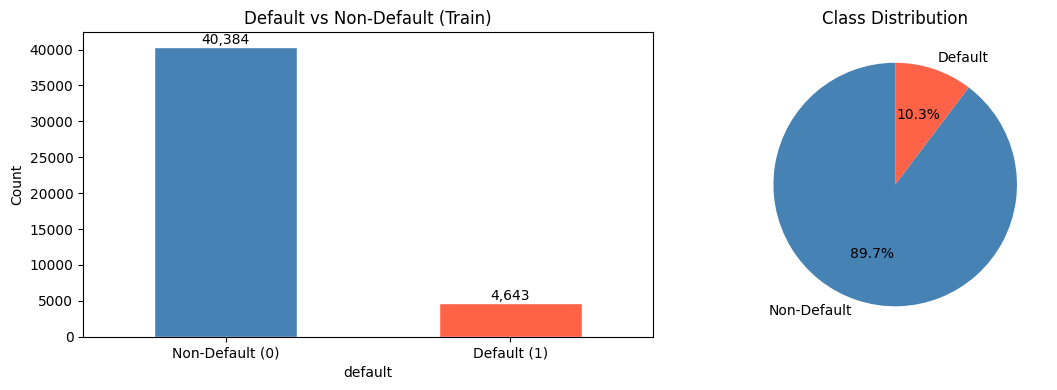

Insight: ~10% default rate — imbalanced dataset, will need scale_pos_weight in XGBoost


In [ ]:
#   EDA 1  Default rate visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
train_flags['default'].value_counts().plot(kind='bar', ax=axes[0],
                                            color=['steelblue','tomato'],
                                            edgecolor='white')
axes[0].set_title('Default vs Non-Default (Train)')
axes[0].set_xticklabels(['Non-Default (0)', 'Default (1)'], rotation=0)
axes[0].set_ylabel('Count')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')

# Pie
axes[1].pie([40384, 4643], labels=['Non-Default', 'Default'],
            autopct='%1.1f%%', colors=['steelblue','tomato'], startangle=90)
axes[1].set_title('Class Distribution')

plt.tight_layout()
plt.show()
print("Insight: ~10% default rate — imbalanced dataset, will need scale_pos_weight in XGBoost")

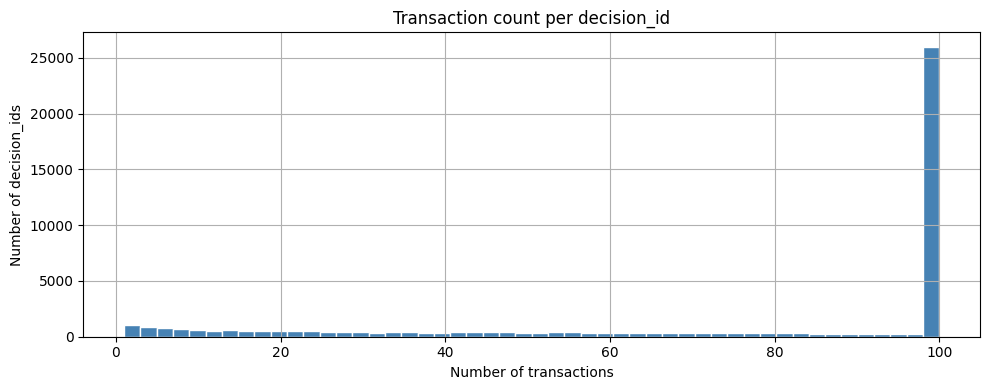

Insight: Hard cap at 100 transactions — Navi truncated the ledger per decision_id
IDs at exactly 100 txns: 25842
IDs with < 5 txns      : 1917


In [ ]:
# EDA 2  Transactions per decision_id distribution
fig, ax = plt.subplots(figsize=(10, 4))
txn_counts.hist(bins=50, ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Transaction count per decision_id')
ax.set_xlabel('Number of transactions')
ax.set_ylabel('Number of decision_ids')
plt.tight_layout()
plt.show()
print("Insight: Hard cap at 100 transactions — Navi truncated the ledger per decision_id")
print(f"IDs at exactly 100 txns: {(txn_counts == 100).sum()}")
print(f"IDs with < 5 txns      : {(txn_counts < 5).sum()}")

In [ ]:
#  EDA 3  Merge ledger with train labels for behavioral analysis
train_ledger = ledger.merge(
    train_flags[['decision_id', 'default']],
    on='decision_id',
    how='inner'
)
print("Train ledger shape:", train_ledger.shape)
print(train_ledger['default'].value_counts())

Train ledger shape: (3305682, 9)
default
0.0000    2977586
1.0000     328096
Name: count, dtype: int64


Balance stats by default label:
               mean    median           std           min
default                                                  
0.0000   42386.0600 3886.1400 11286786.2100 -9242332.1000
1.0000  616855.9900 2088.9000 68618728.6300  -917537.4800


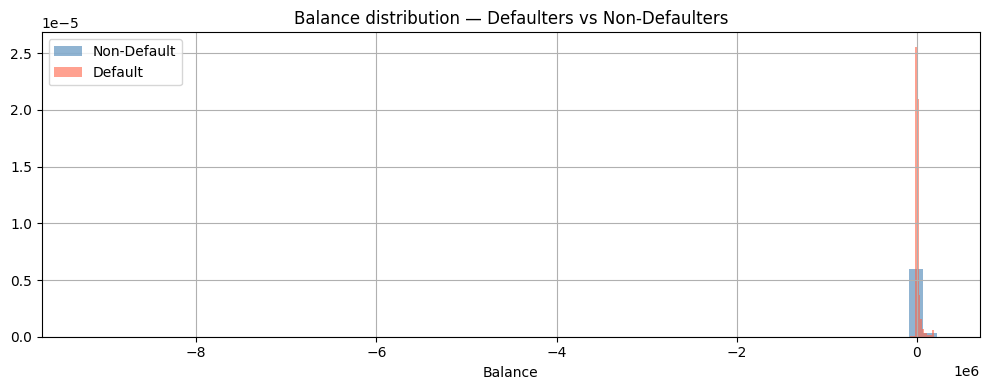

In [ ]:
#  EDA 4  Balance behavior: defaulters

balance_by_default = (
    train_ledger.groupby('default')['balance']
    .agg(['mean', 'median', 'std', 'min'])
    .round(2)
)
print("Balance stats by default label:")
print(balance_by_default)

# Visualize
fig, ax = plt.subplots(figsize=(10, 4))
for label, color, name in [(0, 'steelblue', 'Non-Default'), (1, 'tomato', 'Default')]:
    subset = train_ledger[train_ledger['default'] == label]['balance'].dropna()
    subset.clip(upper=subset.quantile(0.99)).hist(
        bins=60, ax=ax, alpha=0.6, color=color, label=name, density=True
    )
ax.set_title('Balance distribution — Defaulters vs Non-Defaulters')
ax.set_xlabel('Balance')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# EDA 5 — Debit vs Credit behavior by default label
debit_credit = train_ledger.groupby('default').agg(
    avg_debit  = ('debit',  'mean'),
    avg_credit = ('credit', 'mean'),
    total_debit_txns  = ('debit',  'count'),
    total_credit_txns = ('credit', 'count')
).round(2)
print("Debit/Credit behavior by default:")
print(debit_credit)

Debit/Credit behavior by default:
         avg_debit  avg_credit  total_debit_txns  total_credit_txns
default                                                            
0.0000   6062.7200  17170.9700           2005902             968233
1.0000   2022.4400   4279.4200            221260             106531


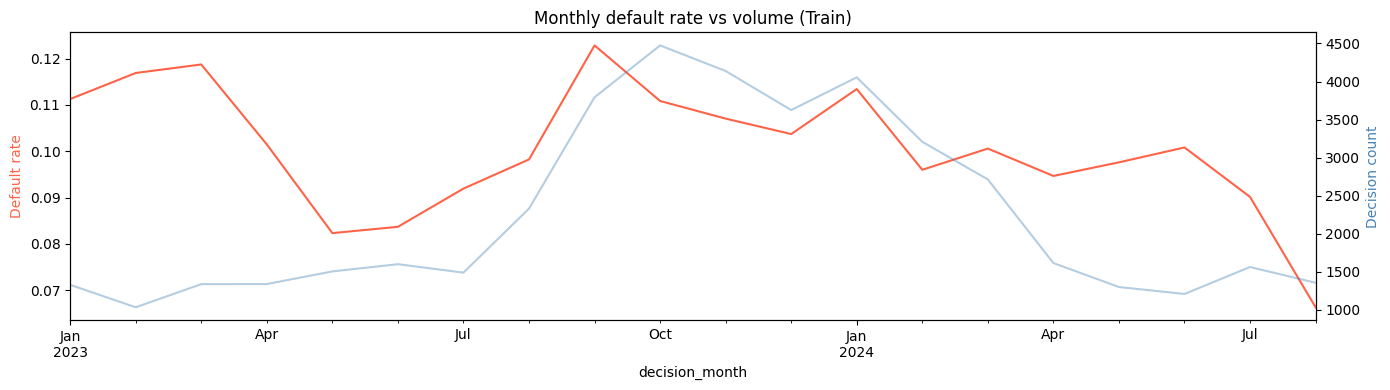

In [ ]:
# EDA 6 — Decision date trends
# Are defaults concentrated at any particular date range?
train_flags['decision_month'] = pd.to_datetime(train_flags['decision_date']).dt.to_period('M')
monthly = train_flags.groupby('decision_month')['default'].agg(['mean', 'count'])
monthly.columns = ['default_rate', 'count']

fig, ax1 = plt.subplots(figsize=(14, 4))
ax2 = ax1.twinx()
monthly['default_rate'].plot(ax=ax1, color='tomato', label='Default rate')
monthly['count'].plot(ax=ax2, color='steelblue', alpha=0.4, label='Volume')
ax1.set_title('Monthly default rate vs volume (Train)')
ax1.set_ylabel('Default rate', color='tomato')
ax2.set_ylabel('Decision count', color='steelblue')
plt.tight_layout()
plt.show()

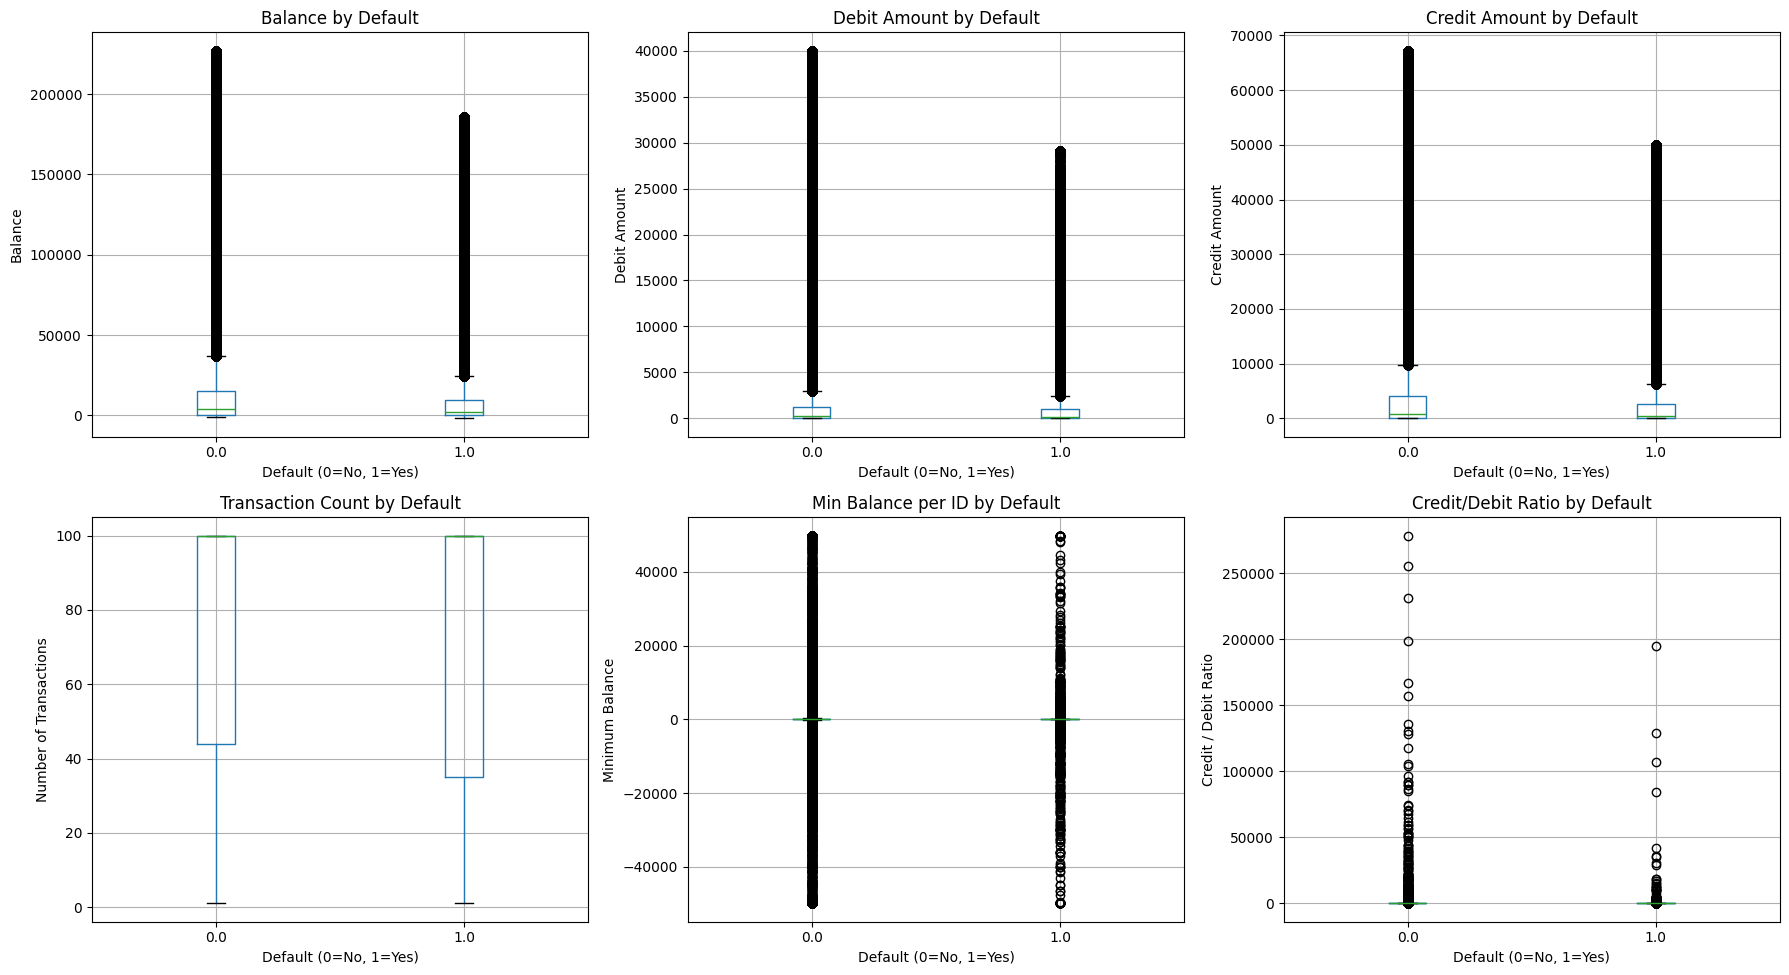

In [ ]:
#  Boxplots for EDA
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Balance distribution by default
train_ledger.groupby('default')['balance'].apply(
    lambda x: x.clip(x.quantile(0.01), x.quantile(0.99))
).reset_index(level=0).boxplot(column='balance', by='default', ax=axes[0,0])
axes[0,0].set_title('Balance by Default')
axes[0,0].set_xlabel('Default (0=No, 1=Yes)')
axes[0,0].set_ylabel('Balance')

# 2. Debit amount by default
train_ledger.dropna(subset=['debit']).groupby('default')['debit'].apply(
    lambda x: x.clip(0, x.quantile(0.99))
).reset_index(level=0).boxplot(column='debit', by='default', ax=axes[0,1])
axes[0,1].set_title('Debit Amount by Default')
axes[0,1].set_xlabel('Default (0=No, 1=Yes)')
axes[0,1].set_ylabel('Debit Amount')

# 3. Credit amount by default
train_ledger.dropna(subset=['credit']).groupby('default')['credit'].apply(
    lambda x: x.clip(0, x.quantile(0.99))
).reset_index(level=0).boxplot(column='credit', by='default', ax=axes[0,2])
axes[0,2].set_title('Credit Amount by Default')
axes[0,2].set_xlabel('Default (0=No, 1=Yes)')
axes[0,2].set_ylabel('Credit Amount')

# 4. Transaction count per decision_id by default
txn_count_with_label = (
    train_ledger.groupby(['decision_id', 'default'])
    .size()
    .reset_index(name='txn_count')
)
txn_count_with_label.boxplot(column='txn_count', by='default', ax=axes[1,0])
axes[1,0].set_title('Transaction Count by Default')
axes[1,0].set_xlabel('Default (0=No, 1=Yes)')
axes[1,0].set_ylabel('Number of Transactions')

# 5. Min balance per decision_id by default
min_balance_by_id = (
    train_ledger.groupby(['decision_id', 'default'])['balance']
    .min()
    .reset_index()
)
min_balance_by_id['balance'] = min_balance_by_id['balance'].clip(
    min_balance_by_id['balance'].quantile(0.01),
    min_balance_by_id['balance'].quantile(0.99)
)
min_balance_by_id.boxplot(column='balance', by='default', ax=axes[1,1])
axes[1,1].set_title('Min Balance per ID by Default')
axes[1,1].set_xlabel('Default (0=No, 1=Yes)')
axes[1,1].set_ylabel('Minimum Balance')

# 6. Credit to debit ratio per decision_id by default
ratio_df = (
    train_ledger.groupby(['decision_id', 'default'])
    .agg(total_credit=('credit', 'sum'), total_debit=('debit', 'sum'))
    .reset_index()
)
ratio_df['credit_debit_ratio'] = (
    ratio_df['total_credit'] / (ratio_df['total_debit'] + 1)
).clip(0, ratio_df['total_credit'].quantile(0.99))
ratio_df.boxplot(column='credit_debit_ratio', by='default', ax=axes[1,2])
axes[1,2].set_title('Credit/Debit Ratio by Default')
axes[1,2].set_xlabel('Default (0=No, 1=Yes)')
axes[1,2].set_ylabel('Credit / Debit Ratio')

plt.suptitle('')
plt.tight_layout()
plt.show()

## Feature Engineering

### Handling nulls in balance for ledger

1.   Sorting and grouping per bank account for each transaction date
2.   Forward filling and imputation



In [ ]:
ledger = ledger.sort_values(['decision_id', 'txnDate']).reset_index(drop=True)
ledger['balance'] = (
    ledger.groupby(['decision_id', 'bankAccount'])['balance']
    .ffill()
)
# Fill remaining nulls with per-person median, then 0
ledger['balance'] = ledger['balance'].fillna(
    ledger.groupby('decision_id')['balance'].transform('median')
)
ledger['balance'] = ledger['balance'].fillna(0)
#  Days before decision per transaction
ledger['days_before_decision'] = (
    ledger['decision_date'] - ledger['txnDate']
).dt.days

print("\nBalance nulls     :", ledger['balance'].isna().sum())
print("Ledger shape final:", ledger.shape)
print("\nPost-decision txns:", (ledger['days_before_decision'] < 0).sum())
print("Pre-decision txns :", (ledger['days_before_decision'] >= 0).sum())


Balance nulls     : 0
Ledger shape final: (3426965, 9)

Post-decision txns: 374673
Pre-decision txns : 3052292


In [ ]:
ledger['days_before_decision'].value_counts()
ledger[ledger['days_before_decision'] < 0]

,decision_id,decision_date,bankAccount,txnDate,txnTimestamp,debit,credit,balance,days_before_decision
16,0002d978-da31-4262-8c0b-38c584bda4d2,2024-01-01,state bank of india_account_xx21,2024-01-05,1704466223205.0000,18819.0000,NaN,2525.8800,-4
51,0004812f-5772-4a69-bf7d-839721d11642,2023-10-29,icici bank limited_account_xx74,2023-10-30,1698634975188.0000,150.0000,NaN,0.0000,-1
52,0004812f-5772-4a69-bf7d-839721d11642,2023-10-29,icici bank limited_account_xx74,2023-10-31,1698747583420.0000,200.0000,NaN,0.0000,-2
53,0004812f-5772-4a69-bf7d-839721d11642,2023-10-29,icici bank limited_account_xx74,2023-10-31,1698731368819.0000,160.0000,NaN,0.0000,-2
54,0004812f-5772-4a69-bf7d-839721d11642,2023-10-29,icici bank limited_account_xx74,2023-11-01,1698815915112.0000,NaN,838.0000,0.0000,-3
...,...,...,...,...,...,...,...,...,...
3426960,fffb55e9-1e83-4bc6-80de-631f4887a654,2024-03-30,kotak mahindra bank limited_account_xx14,2024-04-04,1712230429472.0000,175.0000,NaN,215407.7800,-5
3426961,fffb55e9-1e83-4bc6-80de-631f4887a654,2024-03-30,kotak mahindra bank limited_account_xx14,2024-04-04,1712226142230.0000,40.0000,NaN,215582.7800,-5
3426962,fffb55e9-1e83-4bc6-80de-631f4887a654,2024-03-30,kotak mahindra bank limited_account_xx14,2024-04-05,1712328054743.0000,20.0000,NaN,214735.7800,-6
3426963,fffb55e9-1e83-4bc6-80de-631f4887a654,2024-03-30,kotak mahindra bank limited_account_xx14,2024-04-05,1712326109350.0000,40.0000,NaN,214755.7800,-6


### Changed approach Feature Engineering

In [ ]:
# Feature Engineering

#  Split ledger into pre-decision and full
pre  = ledger[ledger['days_before_decision'] >= 0].copy()  # pre decision only at the time when decision was taken
full = ledger.copy()                                        # all transactions

print("Pre-decision rows :", len(pre))
print("Full ledger rows  :", len(full))



Pre-decision rows : 3052292
Full ledger rows  : 3426965


### Pre-decision feature

In [ ]:
# Trying to understand what navi sees at the tine iof decisioning

# Pre: Balance aggregates
pre_balance = (
    pre.groupby('decision_id')['balance']
    .agg(
        pre_mean_balance   = 'mean',
        pre_median_balance = 'median',
        pre_std_balance    = 'std',
        pre_min_balance    = 'min',
        pre_max_balance    = 'max',
    )
    .reset_index()
)

pre_neg_balance = (
    pre[pre['balance'] < 0]
    .groupby('decision_id')
    .size()
    .reset_index(name='pre_negative_balance_count')
)

pre_balance = pre_balance.merge(pre_neg_balance, on='decision_id', how='left')
pre_balance['pre_negative_balance_count'] = pre_balance['pre_negative_balance_count'].fillna(0)
print("Pre balance features    :", pre_balance.shape)



Pre balance features    : (46163, 7)


### Pre Credit/Debit Features

In [ ]:
#  Pre: Debit / credit features
pre_debit = (
    pre.dropna(subset=['debit'])
    .groupby('decision_id')['debit']
    .agg(
        pre_total_debit  = 'sum',
        pre_avg_debit    = 'mean',
        pre_num_debits   = 'count',
        pre_max_debit    = 'max',
    )
    .reset_index()
)

pre_credit = (
    pre.dropna(subset=['credit'])
    .groupby('decision_id')['credit']
    .agg(
        pre_total_credit  = 'sum',
        pre_avg_credit    = 'mean',
        pre_num_credits   = 'count',
        pre_max_credit    = 'max',
    )
    .reset_index()
)

pre_cashflow = pre_debit.merge(pre_credit, on='decision_id', how='outer')
pre_cashflow['pre_credit_debit_ratio'] = (
    pre_cashflow['pre_total_credit'] / (pre_cashflow['pre_total_debit'] + 1)
)
print("Pre cashflow features   :", pre_cashflow.shape)

# Cashflow is an indicator of truly how much credit is present and how much debit is owed

Pre cashflow features   : (46162, 10)


### Pre - Activity Features

In [ ]:
#  Pre: Activity features
pre_activity = (
    pre.groupby('decision_id')
    .agg(
        pre_total_txns    = ('txnDate', 'count'),
        pre_num_accounts  = ('bankAccount', 'nunique'),
        pre_first_txn     = ('txnDate', 'min'),
        pre_last_txn      = ('txnDate', 'max'),
        decision_date     = ('decision_date', 'first'),
    )
    .reset_index()
)

pre_activity['pre_history_days'] = (
    pre_activity['pre_last_txn'] -
    pre_activity['pre_first_txn']
).dt.days

pre_activity['days_since_last_txn'] = (
    pre_activity['decision_date'] -
    pre_activity['pre_last_txn']
).dt.days

pre_activity.drop(
    columns=['pre_first_txn', 'pre_last_txn', 'decision_date'],
    inplace=True
)
print(" Pre activity features   :", pre_activity.shape)

 Pre activity features   : (46163, 5)


### Pre-recency Feature

In [ ]:
#  Pre: Recency features (last 30 / 60 days before decision)
last30 = pre[pre['days_before_decision'] <= 30]
pre_last30 = (
    last30.groupby('decision_id')['balance']
    .agg(last30_mean_balance='mean', last30_min_balance='min')
    .reset_index()
)

last60 = pre[pre['days_before_decision'] <= 60]
pre_last60 = (
    last60.groupby('decision_id')['balance']
    .agg(last60_mean_balance='mean', last60_min_balance='min')
    .reset_index()
)
print(" Pre recency features    :", pre_last30.shape, pre_last60.shape)

 Pre recency features    : (45335, 3) (45907, 3)


### Pre-Balance Trend

In [ ]:
#  Pre: Balance trend
def compute_slope(group):
    if len(group) < 2:
        return 0.0
    x = np.arange(len(group))
    slope, _, _, _, _ = linregress(x, group['balance'].fillna(0).values)
    return slope

print("Computing pre balance trend...")
pre_trend = (
    pre.groupby('decision_id')
    .apply(compute_slope, include_groups=False)
    .reset_index()
    .rename(columns={0: 'pre_balance_trend'})
)
print("Pre balance trend       :", pre_trend.shape)


Computing pre balance trend...
Pre balance trend       : (46163, 2)


### Pre Income Checks

In [ ]:
# If customer has regular intervals of credit means he is less likely to default and can pay back his loans
pre_income = (
    pre.dropna(subset=['credit'])
    .groupby('decision_id')
    .agg(
        pre_num_credit_months = ('txnDate', lambda x: pd.to_datetime(x).dt.to_period('M').nunique()),
        pre_max_single_credit = ('credit', 'max'),
    )
    .reset_index()
)
print("Pre income features     :", pre_income.shape)

Pre income features     : (45017, 3)


### Pre Transaction Gaps

In [ ]:
pre['prev_txn_date'] = pre.groupby('decision_id')['txnDate'].shift(1)
pre['days_between_txns'] = (pre['txnDate'] - pre['prev_txn_date']).dt.days

pre_gaps = (
    pre.groupby('decision_id')['days_between_txns']
    .agg(
        pre_avg_gap = 'mean',
        pre_max_gap = 'max',
    )
    .reset_index()
)
print("Pre gap features        :", pre_gaps.shape)

Pre gap features        : (46163, 3)


### Debt Outlier Checks

In [ ]:
# Pre: Large unusual debits
def large_debit_count(x):
    if len(x) < 2:
        return 0
    threshold = x.mean() + 2 * x.std() # outlier formula
    return int((x > threshold).sum())

pre_volatility = (
    pre.dropna(subset=['debit'])
    .groupby('decision_id')['debit']
    .apply(large_debit_count, include_groups=False)
    .reset_index()
    .rename(columns={'debit': 'pre_large_debit_count'})
)
print("Pre volatility features :", pre_volatility.shape)

Pre volatility features : (45450, 2)


### Consolidating the feature matrix

In [ ]:
full_activity = (
    full.groupby('decision_id')
    .agg(
        full_total_txns   = ('txnDate', 'count'),
        full_num_accounts = ('bankAccount', 'nunique'),
        full_history_days = ('txnDate', lambda x: (x.max() - x.min()).days),
    )
    .reset_index()
)
print("Full activity features  :", full_activity.shape)

#  Full: Post-decision transaction count
post = ledger[ledger['days_before_decision'] < 0]
post_activity = (
    post.groupby('decision_id')
    .size()
    .reset_index(name='post_decision_txn_count')
)
print("Post decision features  :", post_activity.shape)

# Full: Derived features
# These are computed after the merge


# Merging all features

all_dfs = [
    pre_balance,
    pre_cashflow,
    pre_activity,
    pre_last30,
    pre_last60,
    pre_trend,
    pre_income,
    pre_gaps,
    pre_volatility,
    full_balance,
    full_activity,
    post_activity,
]

feature_matrix = reduce(
    lambda left, right: left.merge(right, on='decision_id', how='left'),
    all_dfs
)

#  Derived features
feature_matrix['balance_deterioration'] = (
    feature_matrix['pre_mean_balance'] - feature_matrix['last30_mean_balance']
)
feature_matrix['balance_range'] = (
    feature_matrix['pre_max_balance'] - feature_matrix['pre_min_balance']
)
feature_matrix['txn_intensity'] = (
    feature_matrix['pre_total_txns'] / (feature_matrix['pre_history_days'] + 1)
)
feature_matrix['post_pre_txn_ratio'] = (
    feature_matrix['post_decision_txn_count'] / (feature_matrix['pre_total_txns'] + 1)
)

#  Add missing decision_ids
all_ids = flags[['decision_id']].copy()
feature_matrix = all_ids.merge(feature_matrix, on='decision_id', how='left')

#  Flag features
missing_ids = set(flags['decision_id']) - set(pre['decision_id'])
feature_matrix['is_missing_history'] = (
    feature_matrix['decision_id'].isin(missing_ids)
).astype(int)
feature_matrix['has_last30_data'] = (
    feature_matrix['decision_id'].isin(pre_last30['decision_id'])
).astype(int)
feature_matrix['has_last60_data'] = (
    feature_matrix['decision_id'].isin(pre_last60['decision_id'])
).astype(int)

#  Fill NaNs
feature_matrix = feature_matrix.fillna(feature_matrix.median(numeric_only=True))

print("\n----------------------------------------\n")
print("FEATURE MATRIX COMPLETE")
print("Shape      :", feature_matrix.shape)
print("Null count :", feature_matrix.isnull().sum().sum())
print("Columns    :", feature_matrix.columns.tolist())
print("\n----------------------------------------\n")


Full activity features  : (46310, 4)
Post decision features  : (24025, 2)

----------------------------------------

FEATURE MATRIX COMPLETE
Shape      : (51068, 46)
Null count : 0
Columns    : ['decision_id', 'pre_mean_balance', 'pre_median_balance', 'pre_std_balance', 'pre_min_balance', 'pre_max_balance', 'pre_negative_balance_count', 'pre_total_debit', 'pre_avg_debit', 'pre_num_debits', 'pre_max_debit', 'pre_total_credit', 'pre_avg_credit', 'pre_num_credits', 'pre_max_credit', 'pre_credit_debit_ratio', 'pre_total_txns', 'pre_num_accounts', 'pre_history_days', 'days_since_last_txn', 'last30_mean_balance', 'last30_min_balance', 'last60_mean_balance', 'last60_min_balance', 'pre_balance_trend', 'pre_num_credit_months', 'pre_max_single_credit', 'pre_avg_gap', 'pre_max_gap', 'pre_large_debit_count', 'full_mean_balance', 'full_min_balance', 'full_max_balance', 'full_std_balance', 'full_negative_balance_count', 'full_total_txns', 'full_num_accounts', 'full_history_days', 'post_decision_txn_

### Model Training

In [ ]:

#Train/OOT Split + XGBoost + LightGBM + Blending both


#  Step 1: Train / OOT split
train_ids = set(train_flags['decision_id'])
oot_ids   = set(oot_flags['decision_id'])

train_features = feature_matrix[feature_matrix['decision_id'].isin(train_ids)].copy()
oot_features   = feature_matrix[feature_matrix['decision_id'].isin(oot_ids)].copy()

train_features = train_features.merge(
    train_flags[['decision_id', 'default']], on='decision_id', how='left'
)

feature_cols = [c for c in feature_matrix.columns if c != 'decision_id']

X   = train_features[feature_cols]
y   = train_features['default']
X_oot = oot_features[feature_cols]

print("X shape      :", X.shape)
print("y shape      :", y.shape)
print("X_oot shape  :", X_oot.shape)
print("Default rate :", y.mean().round(4))
print("Columns match:", list(X.columns) == list(X_oot.columns))

#  Step 2: XGBoost
scale_pos_weight = (y == 0).sum() / (y == 1).sum()
print(f"\nscale_pos_weight: {scale_pos_weight:.2f}")

xgb_params = {
    'n_estimators'        : 1000,
    'max_depth'           : 6,
    'learning_rate'       : 0.02,
    'subsample'           : 0.8,
    'colsample_bytree'    : 0.8,
    'min_child_weight'    : 5,
    'gamma'               : 0.1,
    'reg_alpha'           : 0.1,
    'reg_lambda'          : 1.0,
    'scale_pos_weight'    : scale_pos_weight,
    'early_stopping_rounds': 50,
    'eval_metric'         : 'auc',
    'random_state'        : 42,
    'n_jobs'              : -1,
}

final_xgb_params = {k: v for k, v in xgb_params.items()
                    if k != 'early_stopping_rounds'}

skf  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X))
fold_aucs = []

print("\nTraining XGBoost 5-fold...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = xgb.XGBClassifier(**xgb_params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    val_preds          = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds
    fold_auc           = roc_auc_score(y_val, val_preds)
    fold_aucs.append(fold_auc)
    print(f"  Fold {fold+1} AUC: {fold_auc:.4f}")

xgb_mean_auc = np.mean(fold_aucs)
xgb_gini     = 2 * xgb_mean_auc - 1
fpr, tpr, _  = roc_curve(y, oof_preds)
xgb_ks       = (tpr - fpr).max()
print(f"\nXGBoost Mean AUC : {xgb_mean_auc:.4f}")
print(f"XGBoost Gini     : {xgb_gini:.4f}")
print(f"XGBoost KS       : {xgb_ks:.4f}")

#  Step 3: LightGBM
lgb_params = {
    'n_estimators'     : 500,
    'max_depth'        : 6,
    'learning_rate'    : 0.05,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'min_child_samples': 20,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 1.0,
    'scale_pos_weight' : scale_pos_weight,
    'random_state'     : 42,
    'n_jobs'           : -1,
    'verbose'          : -1,
}

lgb_oof_preds = np.zeros(len(X))
lgb_fold_aucs = []

print("\nTraining LightGBM 5-fold...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    lgb_model = lgb.LGBMClassifier(**lgb_params)
    lgb_model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.log_evaluation(0)]
    )

    val_preds              = lgb_model.predict_proba(X_val)[:, 1]
    lgb_oof_preds[val_idx] = val_preds
    fold_auc               = roc_auc_score(y_val, val_preds)
    lgb_fold_aucs.append(fold_auc)
    print(f"  Fold {fold+1} AUC: {fold_auc:.4f}")

lgb_mean_auc = np.mean(lgb_fold_aucs)
lgb_gini     = 2 * lgb_mean_auc - 1
fpr_l, tpr_l, _ = roc_curve(y, lgb_oof_preds)
lgb_ks       = (tpr_l - fpr_l).max()
print(f"\nLightGBM Mean AUC : {lgb_mean_auc:.4f}")
print(f"LightGBM Gini     : {lgb_gini:.4f}")
print(f"LightGBM KS       : {lgb_ks:.4f}")

#  Step 4: Blending both
blended_oof  = 0.5 * oof_preds + 0.5 * lgb_oof_preds
blended_auc  = roc_auc_score(y, blended_oof)
blended_gini = 2 * blended_auc - 1
fpr_b, tpr_b, _ = roc_curve(y, blended_oof)
blended_ks   = (tpr_b - fpr_b).max()

#  Summary
print("\n---------------------------------------------------------------------------\n")
print(f"XGBoost  AUC: {xgb_mean_auc:.4f}  Gini: {xgb_gini:.4f}  KS: {xgb_ks:.4f}")
print(f"LightGBM AUC: {lgb_mean_auc:.4f}  Gini: {lgb_gini:.4f}  KS: {lgb_ks:.4f}")
print(f"Blended  AUC: {blended_auc:.4f}  Gini: {blended_gini:.4f}  KS: {blended_ks:.4f}")
print("\n---------------------------------------------------------------------------\n")

#  Step 5: Final models on full train data
print("\nTraining final models on full train data...")

final_xgb = xgb.XGBClassifier(**final_xgb_params)
final_xgb.fit(X, y, verbose=False)

final_lgb = lgb.LGBMClassifier(**lgb_params)
final_lgb.fit(X, y, callbacks=[lgb.log_evaluation(0)])

#  Step 6: OOT predictions
xgb_oot   = final_xgb.predict_proba(X_oot)[:, 1]
lgb_oot   = final_lgb.predict_proba(X_oot)[:, 1]
blend_oot = 0.5 * xgb_oot + 0.5 * lgb_oot

# Save all 3
pd.DataFrame({'decision_id': oot_features['decision_id'].values,
              'predicted_PD': xgb_oot}).to_csv('/content/submission_xgb.csv', index=False)
pd.DataFrame({'decision_id': oot_features['decision_id'].values,
              'predicted_PD': lgb_oot}).to_csv('/content/submission_lgb.csv', index=False)
pd.DataFrame({'decision_id': oot_features['decision_id'].values,
              'predicted_PD': blend_oot}).to_csv('/content/submission_blended.csv', index=False)

print("submission_xgb.csv saved")
print("submission_lgb.csv saved")
print("submission_blended.csv saved")

#  Step 7: Save pickles
with open('/content/navi_xgb_model.pkl', 'wb') as f:
    pickle.dump(final_xgb, f)
with open('/content/navi_lgb_model.pkl', 'wb') as f:
    pickle.dump(final_lgb, f)
print("navi_xgb_model.pkl saved")
print("navi_lgb_model.pkl saved")



X shape      : (45027, 45)
y shape      : (45027,)
X_oot shape  : (6041, 45)
Default rate : 0.1031
Columns match: True

scale_pos_weight: 8.70

Training XGBoost 5-fold...
  Fold 1 AUC: 0.6505
  Fold 2 AUC: 0.6362
  Fold 3 AUC: 0.6442
  Fold 4 AUC: 0.6191
  Fold 5 AUC: 0.6337

XGBoost Mean AUC : 0.6368
XGBoost Gini     : 0.2735
XGBoost KS       : 0.1865

Training LightGBM 5-fold...
  Fold 1 AUC: 0.6242
  Fold 2 AUC: 0.6219
  Fold 3 AUC: 0.6283
  Fold 4 AUC: 0.5954
  Fold 5 AUC: 0.6114

LightGBM Mean AUC : 0.6162
LightGBM Gini     : 0.2325
LightGBM KS       : 0.1655

---------------------------------------------------------------------------

XGBoost  AUC: 0.6368  Gini: 0.2735  KS: 0.1865
LightGBM AUC: 0.6162  Gini: 0.2325  KS: 0.1655
Blended  AUC: 0.6259  Gini: 0.2519  KS: 0.1783

---------------------------------------------------------------------------


Training final models on full train data...
submission_xgb.csv saved
submission_lgb.csv saved
submission_blended.csv saved
navi_xgb

### Feature Importance Matrix

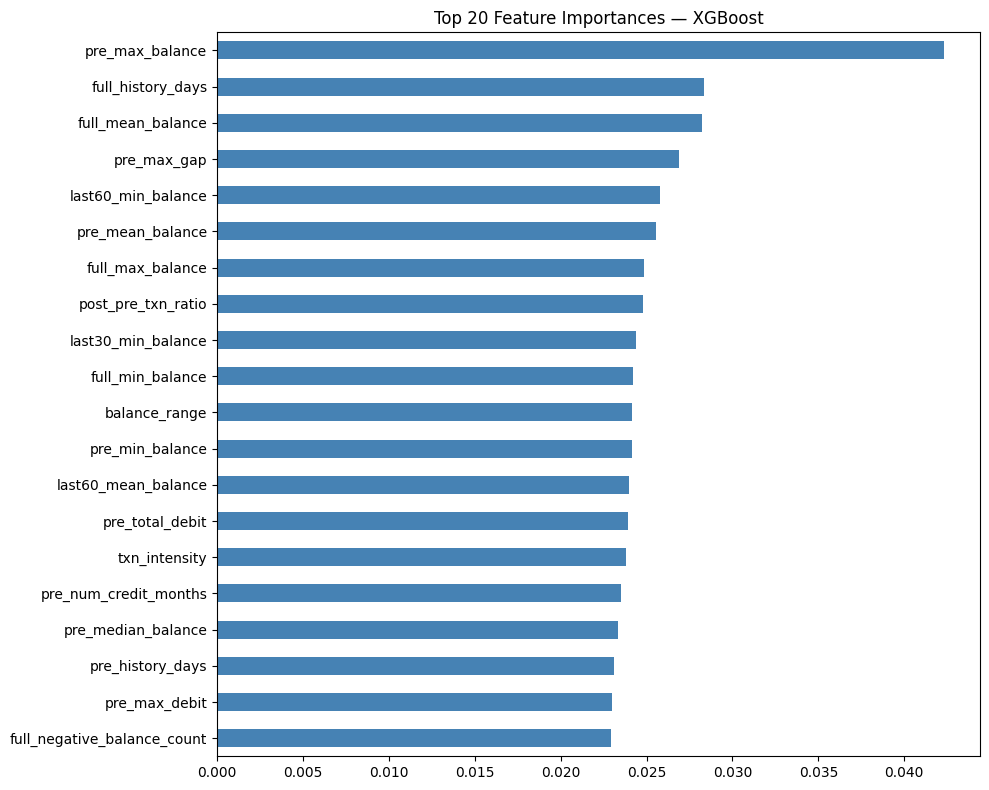


Top 10 features:
pre_max_balance      0.0423
full_history_days    0.0283
full_mean_balance    0.0283
pre_max_gap          0.0269
last60_min_balance   0.0258
pre_mean_balance     0.0255
full_max_balance     0.0249
post_pre_txn_ratio   0.0248
last30_min_balance   0.0244
full_min_balance     0.0242
dtype: float32


In [ ]:
#  Step 8: Feature importance matrix
feat_imp = pd.Series(
    final_xgb.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
feat_imp.head(20).plot(kind='barh', color='steelblue')
plt.title('Top 20 Feature Importances — XGBoost')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nTop 10 features:")
print(feat_imp.head(10))

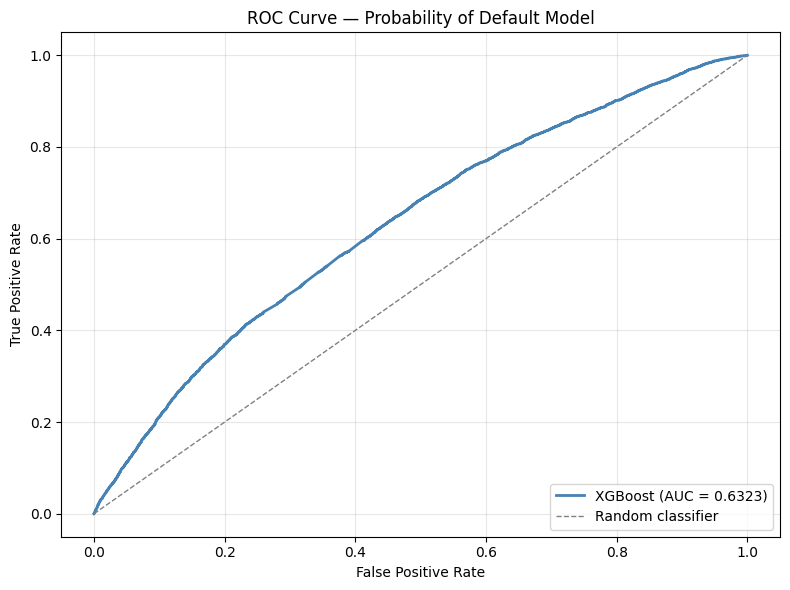

In [ ]:
fpr, tpr, _ = roc_curve(y, oof_preds)
auc_score   = roc_auc_score(y, oof_preds)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'XGBoost (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1, label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Probability of Default Model')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
pre_ledger = ledger[ledger['days_before_decision'] >= 0]
txn_counts = pre_ledger.groupby('decision_id').size()
print(txn_counts.describe())
print("IDs with < 5 pre-decision txns:", (txn_counts < 5).sum())

count   46163.0000
mean       66.1199
std        33.5902
min         1.0000
25%        38.0000
50%        78.0000
75%        98.0000
max       100.0000
dtype: float64
IDs with < 5 pre-decision txns: 2354


### Threshold

In [ ]:
from sklearn.metrics import precision_recall_curve, f1_score

# Method 1 — Maximise F1 score
precisions, recalls, thresholds = precision_recall_curve(y, oof_preds)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_threshold_f1 = thresholds[f1_scores[:-1].argmax()]
print(f"Best threshold (F1)     : {best_threshold_f1:.4f}")

# Method 2 — Maximise KS statistic
fpr, tpr, roc_thresholds = roc_curve(y, oof_preds)
ks_threshold = roc_thresholds[(tpr - fpr).argmax()]
print(f"Best threshold (KS)     : {ks_threshold:.4f}")

# Method 3 — Match expected default rate
# Set threshold so ~10.3% of predictions are flagged as default
threshold_rate = np.percentile(oof_preds, 100 - 10.3)
print(f"Best threshold (rate)   : {threshold_rate:.4f}")

# Evaluate each
for name, thresh in [('F1', best_threshold_f1),
                     ('KS', ks_threshold),
                     ('Rate', threshold_rate)]:
    preds_binary = (oof_preds >= thresh).astype(int)
    from sklearn.metrics import classification_report
    print(f"\n--- Threshold {name}: {thresh:.4f} ---")
    print(classification_report(y, preds_binary))

Best threshold (F1)     : 0.5113
Best threshold (KS)     : 0.4766
Best threshold (rate)   : 0.5674

--- Threshold F1: 0.5113 ---
              precision    recall  f1-score   support

         0.0       0.92      0.77      0.84     40384
         1.0       0.17      0.41      0.24      4643

    accuracy                           0.73     45027
   macro avg       0.54      0.59      0.54     45027
weighted avg       0.84      0.73      0.78     45027


--- Threshold KS: 0.4766 ---
              precision    recall  f1-score   support

         0.0       0.93      0.50      0.66     40384
         1.0       0.14      0.68      0.23      4643

    accuracy                           0.52     45027
   macro avg       0.53      0.59      0.44     45027
weighted avg       0.85      0.52      0.61     45027


--- Threshold Rate: 0.5674 ---
              precision    recall  f1-score   support

         0.0       0.91      0.91      0.91     40384
         1.0       0.19      0.19      0.19   

### Inference

In [ ]:
#  Saving best submission
best_submission = pd.DataFrame({
    'decision_id' : oot_features['decision_id'].values,
    'predicted_PD': xgb_oot
})
best_submission.to_csv('/content/submission_final.csv', index=False)
print(" submission_final.csv saved")
print("Shape:", best_submission.shape)
print(best_submission['predicted_PD'].describe())

#  Save pickle
with open('/content/navi_xgb_final.pkl', 'wb') as f:
    pickle.dump(final_xgb, f)
print(" navi_xgb_final.pkl saved")

#  Save inference code
inference_code = '''
import pickle
import pandas as pd

# Load model
with open("navi_xgb_final.pkl", "rb") as f:
    model = pickle.load(f)

# Load new data — must have same 45 feature columns as training
new_data = pd.read_csv("new_data.csv")
feature_cols = model.get_booster().feature_names
X_new = new_data[feature_cols]

# Predict probability of default
predicted_pd = model.predict_proba(X_new)[:, 1]

# Apply threshold for binary classification
threshold = 0.5
predicted_label = (predicted_pd >= threshold).astype(int)

results = pd.DataFrame({
    "decision_id"    : new_data["decision_id"],
    "predicted_PD"   : predicted_pd,
    "predicted_label": predicted_label
})

print(results.head())
print(f"Average predicted PD: {predicted_pd.mean():.4f}")
'''

with open('/content/inference.py', 'w') as f:
    f.write(inference_code)
print("inference.py saved")

 submission_final.csv saved
Shape: (6041, 2)
count   6041.0000
mean       0.3797
std        0.1682
min        0.0173
25%        0.2445
50%        0.3851
75%        0.5010
max        0.8637
Name: predicted_PD, dtype: float64
 navi_xgb_final.pkl saved
inference.py saved


## End

In [ ]:
import pickle
import pandas as pd

# Load model
with open("navi_xgb_final.pkl", "rb") as f:
    model = pickle.load(f)

# Load new data — must have same 45 feature columns as training
new_data = pd.read_csv("new.csv")
feature_cols = model.feature_names_in_
X_new = new_data[feature_cols]

# Predict probability of default
predicted_pd = model.predict_proba(X_new)[:, 1]

# Apply threshold for binary classification
threshold = 0.5
predicted_label = (predicted_pd >= threshold).astype(int)

results = pd.DataFrame({
    "decision_id"    : new_data["decision_id"],
    "predicted_PD"   : predicted_pd,
    "predicted_label": predicted_label
})

print(results.head())
print(f"Average predicted PD: {predicted_pd.mean():.4f}")

     decision_id  predicted_PD  predicted_label
0  dummy-id-0000        0.0079                0
1  dummy-id-0001        0.0562                0
2  dummy-id-0002        0.1464                0
3  dummy-id-0003        0.0389                0
4  dummy-id-0004        0.0527                0
Average predicted PD: 0.0670


/tmp/ipykernel_5703/4034849403.py:6: UserWarning: [19:53:24] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  model = pickle.load(f)


In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 100  # 100 dummy rows

dummy_data = pd.DataFrame({
    'decision_id'                : [f'dummy-id-{i:04d}' for i in range(n)],
    'pre_mean_balance'           : np.random.uniform(-5000, 100000, n),
    'pre_median_balance'         : np.random.uniform(-5000, 100000, n),
    'pre_std_balance'            : np.random.uniform(0, 50000, n),
    'pre_min_balance'            : np.random.uniform(-500000, 10000, n),
    'pre_max_balance'            : np.random.uniform(0, 500000, n),
    'pre_negative_balance_count' : np.random.randint(0, 20, n),
    'pre_total_debit'            : np.random.uniform(0, 500000, n),
    'pre_avg_debit'              : np.random.uniform(0, 20000, n),
    'pre_num_debits'             : np.random.randint(0, 100, n),
    'pre_max_debit'              : np.random.uniform(0, 100000, n),
    'pre_total_credit'           : np.random.uniform(0, 500000, n),
    'pre_avg_credit'             : np.random.uniform(0, 50000, n),
    'pre_num_credits'            : np.random.randint(0, 100, n),
    'pre_max_credit'             : np.random.uniform(0, 200000, n),
    'pre_credit_debit_ratio'     : np.random.uniform(0, 10, n),
    'pre_total_txns'             : np.random.randint(1, 100, n),
    'pre_num_accounts'           : np.random.randint(1, 5, n),
    'pre_history_days'           : np.random.randint(0, 730, n),
    'days_since_last_txn'        : np.random.randint(0, 180, n),
    'last30_mean_balance'        : np.random.uniform(-10000, 100000, n),
    'last30_min_balance'         : np.random.uniform(-500000, 50000, n),
    'last60_mean_balance'        : np.random.uniform(-10000, 100000, n),
    'last60_min_balance'         : np.random.uniform(-500000, 50000, n),
    'pre_balance_trend'          : np.random.uniform(-1000, 1000, n),
    'pre_num_credit_months'      : np.random.randint(0, 24, n),
    'pre_max_single_credit'      : np.random.uniform(0, 200000, n),
    'pre_avg_gap'                : np.random.uniform(0, 60, n),
    'pre_max_gap'                : np.random.uniform(0, 180, n),
    'pre_large_debit_count'      : np.random.randint(0, 10, n),
    'full_mean_balance'          : np.random.uniform(-5000, 100000, n),
    'full_min_balance'           : np.random.uniform(-500000, 10000, n),
    'full_max_balance'           : np.random.uniform(0, 500000, n),
    'full_std_balance'           : np.random.uniform(0, 50000, n),
    'full_negative_balance_count': np.random.randint(0, 30, n),
    'full_total_txns'            : np.random.randint(1, 100, n),
    'full_num_accounts'          : np.random.randint(1, 5, n),
    'full_history_days'          : np.random.randint(0, 1000, n),
    'post_decision_txn_count'    : np.random.randint(0, 50, n),
    'balance_deterioration'      : np.random.uniform(-50000, 50000, n),
    'balance_range'              : np.random.uniform(0, 500000, n),
    'txn_intensity'              : np.random.uniform(0, 5, n),
    'post_pre_txn_ratio'         : np.random.uniform(0, 3, n),
    'is_missing_history'         : np.random.randint(0, 2, n),
    'has_last30_data'            : np.random.randint(0, 2, n),
    'has_last60_data'            : np.random.randint(0, 2, n),
})

dummy_data.to_csv('new.csv', index=False)
print("Saved new.csv")
print("Shape:", dummy_data.shape)
print(dummy_data.head(3))

Saved new.csv
Shape: (100, 46)
     decision_id  pre_mean_balance  pre_median_balance  pre_std_balance  \
0  dummy-id-0000        34326.7125          -1699.9355       32101.5823   
1  dummy-id-0001        94825.0022          61823.0932        4206.9982   
2  dummy-id-0002        71859.3639          28007.3780        8081.4357   

   pre_min_balance  pre_max_balance  pre_negative_balance_count  \
0     -473642.3222       51561.9344                          16   
1     -229009.1379      451276.4533                           8   
2     -224276.0880      252626.1862                           0   

   pre_total_debit  pre_avg_debit  pre_num_debits  pre_max_debit  \
0      490016.2876      5158.0565              35     45898.8988   
1      246309.0470      3417.7517              25     55730.5369   
2      164375.8051     13372.8644              42     86063.2018   

   pre_total_credit  pre_avg_credit  pre_num_credits  pre_max_credit  \
0       360101.2908      26008.4055               76  

## Part of Older Adopted approach please ignore

### Generating Balance features

In [ ]:
# ── Step 4: KS Statistic ──────────────────────────────────────────────────────
fpr, tpr, thresholds = roc_curve(y, oof_preds)
ks_stat = (tpr - fpr).max()
print(f"KS Stat  : {ks_stat:.4f}")

KS Stat  : 0.2176


### ROC Curve

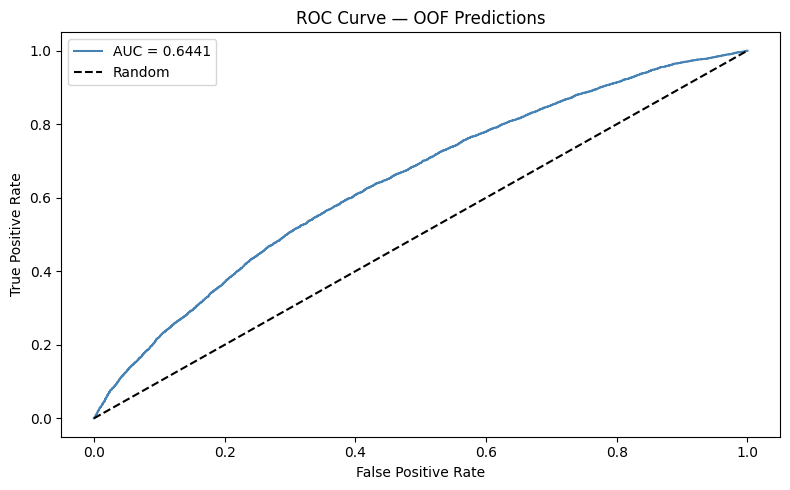

In [ ]:
# ── Step 5: ROC Curve ─────────────────────────────────────────────────────────
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, color='steelblue', label=f'AUC = {mean_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — OOF Predictions')
plt.legend()
plt.tight_layout()
plt.show()

### Feature Importance

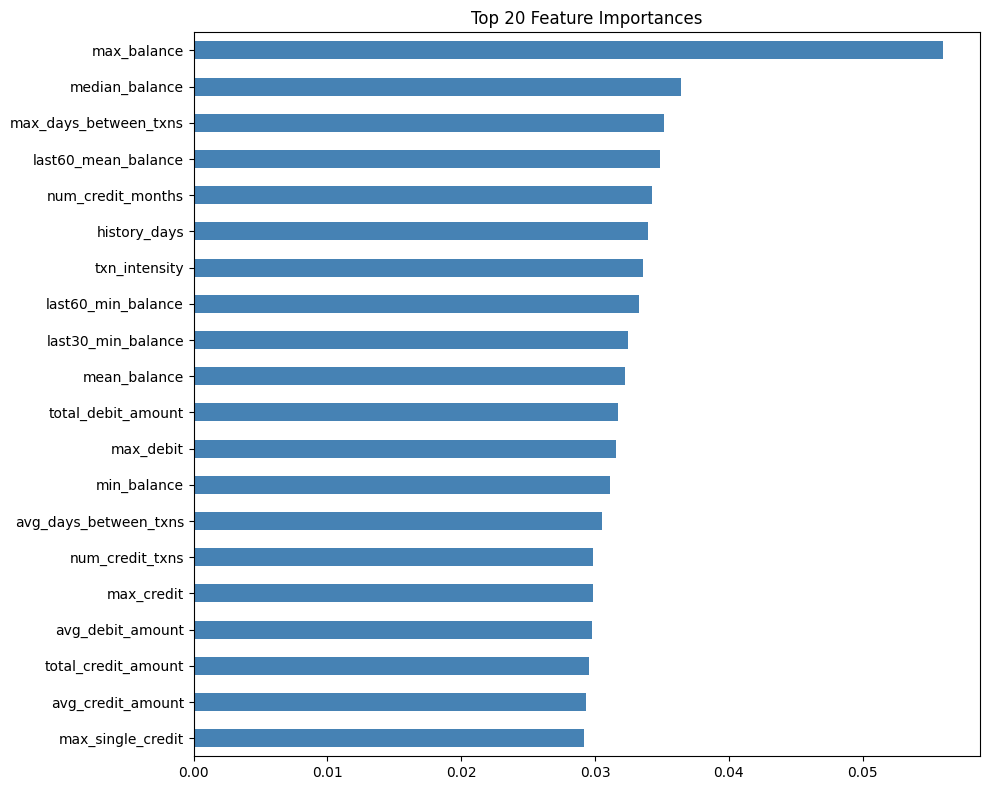


Top 10 features:
max_balance             0.0560
median_balance          0.0364
max_days_between_txns   0.0352
last60_mean_balance     0.0349
num_credit_months       0.0343
history_days            0.0340
txn_intensity           0.0336
last60_min_balance      0.0333
last30_min_balance      0.0325
mean_balance            0.0322
dtype: float32


In [ ]:
# ── Step 6: Feature importance ────────────────────────────────────────────────
# Final model params — no early stopping since we train on full data
final_params = {
    'n_estimators'     : 1000,
    'max_depth'        : 6,
    'learning_rate'    : 0.02,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'min_child_weight' : 5,
    'gamma'            : 0.1,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 1.0,
    'scale_pos_weight' : scale_pos_weight,
    'eval_metric'      : 'auc',
    'random_state'     : 42,
    'n_jobs'           : -1,
}

final_model = xgb.XGBClassifier(**final_params)
final_model.fit(X, y, verbose=False)

feat_imp = pd.Series(
    final_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
feat_imp.head(20).plot(kind='barh', color='steelblue')
plt.title('Top 20 Feature Importances')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nTop 10 features:")
print(feat_imp.head(10))

### OOT Predictions

In [ ]:
# ── Step 7: OOT Predictions ───────────────────────────────────────────────────
oot_preds = final_model.predict_proba(X_oot)[:, 1]

submission = pd.DataFrame({
    'decision_id' : oot_features['decision_id'].values,
    'predicted_PD': oot_preds
})

submission.to_csv('/content/submission.csv', index=False)
print("\nSubmission CSV saved")
print("Shape:", submission.shape)
print(submission.head())
print(submission['predicted_PD'].describe())

# ── Step 8: Save model pickle ─────────────────────────────────────────────────
with open('/content/navi_default_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)
print("\nModel saved as navi_default_model.pkl")


Submission CSV saved
Shape: (6041, 2)
                            decision_id  predicted_PD
0  b3e8cbd1-f940-4216-9ba2-a8cca1cbb791        0.3512
1  020313d1-a2a2-4fb1-9c22-c7e211419ec3        0.1604
2  e06394f2-2054-42fd-a4bc-acf8b08e3c99        0.2783
3  6f1ec6e3-caf9-4e0d-8ddb-da5f7e6b0b83        0.2454
4  ceaa6098-46da-406a-ad29-1c489909355e        0.4584
count   6041.0000
mean       0.3796
std        0.1723
min        0.0174
25%        0.2459
50%        0.3750
75%        0.5079
max        0.8444
Name: predicted_PD, dtype: float64

Model saved as navi_default_model.pkl
